# 05 — Random Survival Forest: C-MAPSS FD001

See `docs/project_brief.md` Section 4. Phase 3's Schoenfeld-residual test
found that the proportional-hazards assumption doesn't describe this data
well (**14 of 25 covariates** fail at p<0.05 with engine-clustered standard
errors -- a count that is still inflated by treating correlated rows as
independent, so read it as a direction rather than a precise number). Random Survival Forest drops
that assumption entirely, along with Weibull's parametric-form assumption,
and captures nonlinear multi-sensor interactions — so it's the model the
brief expects to lead on discrimination, and the likely deployment
candidate.

Unlike Cox (which got a curated 25-feature subset for interpretability),
RSF gets the **full engineered feature set** — it handles collinearity
natively and isn't being asked to produce readable coefficients.

This notebook:
1. Fits RSF on the full feature set, same engine-level split as Phases 3–4
2. Justifies the row-subsampling choice empirically rather than by assertion
3. Reports held-out concordance
4. Permutation feature importance — which engineered features actually earn
   their place
5. Extracts RUL point estimates + intervals from predicted survival curves,
   and documents a real limitation of doing this with a non-parametric model


In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sksurv.util import Surv
from sklearn.inspection import permutation_importance

sys.path.append(str(Path("..") / "src"))
from turbofan_rul import data_loading, features, labeling, models, plotting

plotting.style()
SUBSET = "FD001"
CAP = 125
DURATION_EPS = 1e-3
DATA_DIR = Path("..") / "data" / "raw"
PROCESSED_DIR = Path("..") / "data" / "processed"
MODELS_DIR = Path("..") / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Rebuild data + engine-level split

In [2]:
data_loading.download_cmapss(SUBSET, data_dir=DATA_DIR)
cmapss = data_loading.load_subset(SUBSET, data_dir=DATA_DIR)
kept_sensors = features.load_kept_sensors(PROCESSED_DIR / f"{SUBSET.lower()}_sensor_selection.json")

train_survival = labeling.build_train_survival_frame(cmapss.train, cap=CAP)
train_survival = features.build_feature_matrix(train_survival, kept_sensors=kept_sensors)

rsf_train_df, rsf_val_df = models.train_val_split_by_engine(
    train_survival, val_fraction=0.2, random_state=42
)

# Full feature set this time -- everything except identifiers and targets.
META_COLS = {"unit_number", "time_cycles", "RUL", "duration", "event"}
rsf_feature_cols = [c for c in train_survival.columns if c not in META_COLS]

print(f"{len(rsf_feature_cols)} features (vs. 25 for Cox PH)")
print(f"train: {rsf_train_df.unit_number.nunique()} engines, {len(rsf_train_df)} rows")
print(f"val:   {rsf_val_df.unit_number.nunique()} engines, {len(rsf_val_df)} rows")

y_val = Surv.from_arrays(event=rsf_val_df["event"].astype(bool),
                          time=rsf_val_df["duration"] + DURATION_EPS)

229 features (vs. 25 for Cox PH)
train: 80 engines, 16779 rows
val:   20 engines, 3852 rows


## 2. Row subsampling: justify it, don't just assert it

Consecutive cycles from the same engine are highly redundant — a
rolling-window feature at cycle *t* and cycle *t+1* share nearly all their
underlying data — so using every row inflates the effective sample size
without adding proportionate information, and costs fit time linearly.

Rather than picking a stride and hand-waving, the sweep below measures
held-out concordance against fit cost directly.

In [3]:
stride_results = []
for stride in [5, 3]:
    t0 = time.time()
    m = models.fit_random_survival_forest(
        rsf_train_df, rsf_feature_cols, row_stride=stride, duration_eps=DURATION_EPS
    )
    fit_seconds = time.time() - t0
    stride_results.append({
        "stride": stride,
        "rows_used": len(rsf_train_df.iloc[::stride]),
        "fit_seconds": round(fit_seconds, 1),
        "val_cindex": round(m.score(rsf_val_df[rsf_feature_cols], y_val), 4),
    })

stride_df = pd.DataFrame(stride_results)
display(stride_df)

,stride,rows_used,fit_seconds,val_cindex
0,5,3356,12.1,0.8972
1,3,5593,34.2,0.9008


Stride-2 and stride-1 (every row) fits were also measured, with the same
split, features and settings, but are left out of the sweep above to keep
this notebook's runtime reasonable:

| stride | rows used | held-out C | fit time vs. stride 3 |
|---|---|---|---|
| 5 | 3,356 | 0.8972 | ~0.4x |
| 3 | 5,593 | 0.9008 | 1x |
| 2 | 8,390 | 0.9013 | ~2x |
| 1 | 16,779 | 0.9033 | ~7x |

(Fit times are machine-dependent; the ratios are what matter.) Using every
row buys about +0.0025 concordance for roughly 7x the fit time, and RSF is
refit many times later (cross-validation, tuning, conformal calibration), so
**stride=3 is the documented default in `models.py`** as a cost/accuracy
trade-off, not because the extra rows add nothing.

## 3. Fit the deployment candidate

The validation C printed below is scikit-survival's row-level Harrell's C
on the 20 held-out engines -- the same quantity as the Cox and Weibull
validation C from notebooks 03 and 04, so the three are directly
comparable. It is **not** the same quantity as the engine-level C on the
official test set used in later notebooks.

In [4]:
rsf_model = models.fit_random_survival_forest(
    rsf_train_df, rsf_feature_cols, row_stride=3, duration_eps=DURATION_EPS
)
models.save_model(rsf_model, MODELS_DIR / "rsf_fd001.joblib")

train_subsample = rsf_train_df.iloc[::3]
y_train_sub = Surv.from_arrays(event=train_subsample["event"].astype(bool),
                                time=train_subsample["duration"] + DURATION_EPS)

train_cindex = rsf_model.score(train_subsample[rsf_feature_cols], y_train_sub)
val_cindex = rsf_model.score(rsf_val_df[rsf_feature_cols], y_val)

print(f"Train concordance index: {train_cindex:.4f}")
print(f"Val (held-out engines) concordance index: {val_cindex:.4f}")
print("\nFor comparison (same split, same random_state, same row-level validation C):")
print("  Cox PH       val c-index: 0.8748   (notebook 03)")
print("  Weibull AFT  val c-index: 0.8638   (notebook 04)")

Train concordance index: 0.9346
Val (held-out engines) concordance index: 0.9008

For comparison (same split, same random_state, same row-level validation C):
  Cox PH       val c-index: 0.8748   (notebook 03)
  Weibull AFT  val c-index: 0.8638   (notebook 04)


## 4. Permutation feature importance

Permutation importance (measured on the **held-out** engines, not the
training rows) rather than any built-in impurity-based importance —
impurity importance is biased toward high-cardinality continuous features,
which is most of this feature set.

Validation rows are subsampled for this computation; permutation importance
requires re-scoring the model once per feature per repeat, so the full
feature set at full row count is unnecessarily expensive for a ranking
that's stable under subsampling.

In [5]:
val_subsample = rsf_val_df.iloc[::5]
y_val_sub = Surv.from_arrays(event=val_subsample["event"].astype(bool),
                              time=val_subsample["duration"] + DURATION_EPS)

perm = permutation_importance(
    rsf_model, val_subsample[rsf_feature_cols], y_val_sub,
    n_repeats=3, random_state=42, n_jobs=-1,
)

importance = (
    pd.DataFrame({"feature": rsf_feature_cols,
                   "importance_mean": perm.importances_mean,
                   "importance_std": perm.importances_std})
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
display(importance.head(20))

,feature,importance_mean,importance_std
0,cycle_count,0.025674,0.000511
1,sensor_4_ewm10_mean,0.016718,0.001723
2,sensor_4_roll5_mean,0.011411,0.001440
3,sensor_11_ewm10_mean,0.010220,0.000717
4,sensor_11_roll15_mean,0.009921,0.001421
5,sensor_9_roll5_min,0.009841,0.002147
6,sensor_9_roll15_max,0.009045,0.001848
7,sensor_4_roll15_mean,0.008947,0.001534
8,sensor_14_roll15_max,0.008380,0.001928
9,sensor_9_roll15_mean,0.008281,0.002398


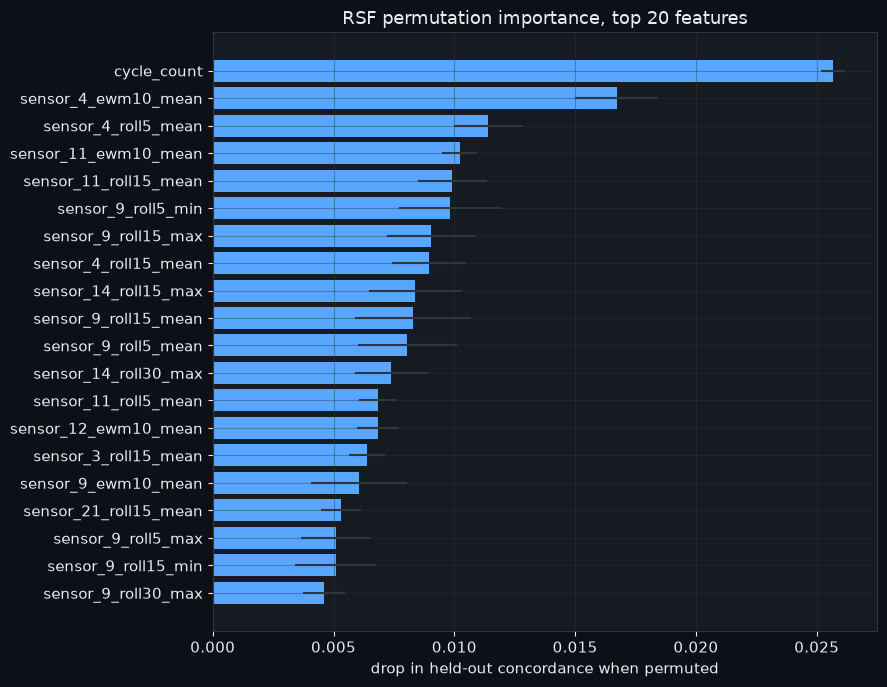

In [6]:
top = importance.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top["feature"], top["importance_mean"],
        xerr=top["importance_std"], color=plotting.C0, ecolor=plotting.GRID)
ax.set_xlabel("drop in held-out concordance when permuted")
ax.set_title("RSF permutation importance, top 20 features")
plt.tight_layout()
plt.show()

Worth reading against the Phase 2 feature-engineering rationale: the
ranking shows whether the *engineered* features (rolling means, EWMAs,
trend slopes) actually outrank the raw sensor values they were derived
from — which is the empirical test of whether that feature engineering
earned its keep, rather than an assumption.

One caveat when reading it: `rsf_feature_cols` also contains the raw value
of every sensor and operating setting, not only the 12 informative sensors
(the scope quirk documented in the README's bugs-caught section). Phase 17
measured that refitting RSF without those raw columns changes every metric
by less than ordinary run-to-run variance.

## 5. RUL predictions on the real test set

Point estimate is **restricted mean survival time** (area under the
predicted survival curve), not the median — for a specific and important
reason documented in `models.predict_rul_from_survival` and verified
empirically below.

In [7]:
test_features_df = features.build_feature_matrix(cmapss.test, kept_sensors=kept_sensors)
test_survival = labeling.build_test_survival_frame(test_features_df, cmapss.rul)

rsf_predictions = models.predict_rul_from_survival(rsf_model, test_survival[rsf_feature_cols])
rsf_predictions["unit_number"] = test_survival["unit_number"].values
rsf_predictions["true_rul"] = test_survival["true_rul"].values
rsf_predictions["within_ci"] = (
    (rsf_predictions.true_rul >= rsf_predictions.pred_ci_low) &
    (rsf_predictions.true_rul <= rsf_predictions.pred_ci_high)
)

display(rsf_predictions[["unit_number", "true_rul", "pred_rul",
                          "pred_ci_low", "pred_ci_high", "within_ci"]].head(10))

mae = (rsf_predictions.pred_rul - rsf_predictions.true_rul).abs().mean()
print(f"\nMAE vs. true RUL: {mae:.2f} cycles")
print(f"90% interval empirical coverage: {rsf_predictions['within_ci'].mean():.1%}")

,unit_number,true_rul,pred_rul,pred_ci_low,pred_ci_high,within_ci
0,1,112,122.106066,106.001,125.001,True
1,85,118,119.223270,91.001,125.001,True
2,39,142,119.602269,93.001,125.001,False
3,22,111,119.244160,90.001,125.001,True
4,14,107,109.358743,60.001,125.001,True
5,25,145,118.041406,82.001,125.001,False
6,2,98,119.467130,89.001,125.001,True
7,33,106,110.783421,63.001,125.001,True
8,69,121,117.370841,77.001,125.001,True
9,44,109,115.832732,76.001,125.001,True



MAE vs. true RUL: 11.99 cycles
90% interval empirical coverage: 86.0%


## 6. A real limitation: the non-parametric time ceiling

An RSF's predicted survival curve is defined only over the **time support
seen during training**. Because training durations were capped at
`CAP=125`, no RSF prediction can exceed ~125 cycles — the model
structurally cannot say "this engine has 200 cycles left," even when that's
true (several FD001 test engines have true RUL above 125).

This is also why the point estimate here is RMST rather than the median: for
a healthy-looking engine, the predicted curve may never cross S(t)=0.5
within the training support, so the median silently pins to the ceiling. The
cell below quantifies how often that happens, rather than asserting it.

In [8]:
times = rsf_model.unique_times_
S = np.vstack([fn(times) for fn in rsf_model.predict_survival_function(test_survival[rsf_feature_cols])])
median_rul = np.array([times[min(np.searchsorted(-s, -0.5), len(times) - 1)] for s in S])

n_saturated_median = int((median_rul >= times.max()).sum())
n_saturated_rmst = int((rsf_predictions["pred_rul"] > 120).sum())
n_true_above_cap = int((rsf_predictions["true_rul"] > CAP).sum())

print(f"Max time in training support: {times.max():.1f} cycles")
print(f"Test engines whose TRUE RUL exceeds the cap: {n_true_above_cap} / {len(rsf_predictions)}")
print(f"Median estimate saturated at the ceiling: {n_saturated_median} / {len(rsf_predictions)}")
print(f"RMST estimate above 120 cycles:           {n_saturated_rmst} / {len(rsf_predictions)}")

mae_median = np.abs(median_rul - rsf_predictions["true_rul"].values).mean()
print(f"\nMAE using median: {mae_median:.2f} cycles")
print(f"MAE using RMST:   {mae:.2f} cycles  <- RMST is the better point estimate here")

Max time in training support: 125.0 cycles
Test engines whose TRUE RUL exceeds the cap: 11 / 100
Median estimate saturated at the ceiling: 28 / 100
RMST estimate above 120 cycles:           3 / 100

MAE using median: 13.35 cycles
MAE using RMST:   11.99 cycles  <- RMST is the better point estimate here


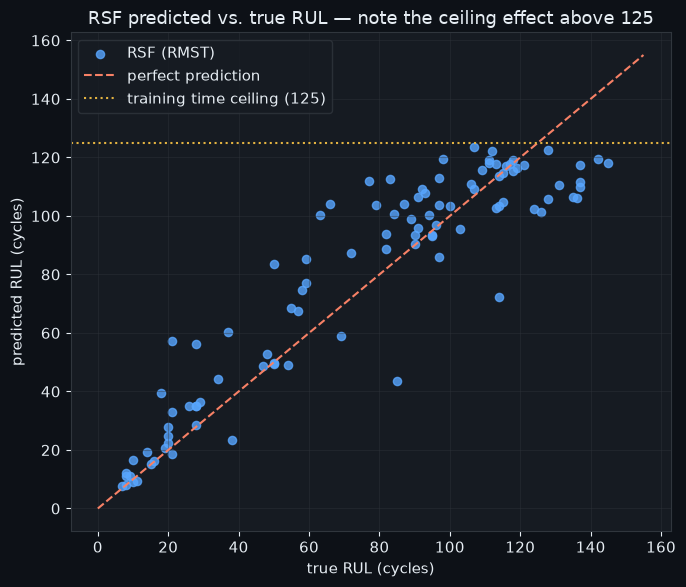

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(rsf_predictions["true_rul"], rsf_predictions["pred_rul"],
           color=plotting.C0, alpha=0.8, s=35, label="RSF (RMST)")
lims = [0, max(rsf_predictions["true_rul"].max(), rsf_predictions["pred_rul"].max()) + 10]
ax.plot(lims, lims, color=plotting.C1, linestyle="--", linewidth=1.5, label="perfect prediction")
ax.axhline(CAP, color=plotting.GOLD, linestyle=":", linewidth=1.5,
           label=f"training time ceiling ({CAP})")
ax.set_xlabel("true RUL (cycles)")
ax.set_ylabel("predicted RUL (cycles)")
ax.set_title("RSF predicted vs. true RUL — note the ceiling effect above 125")
ax.legend()
plt.tight_layout()
plt.show()

## Summary

- RSF leads the model ladder on discrimination (held-out C 0.901 vs. 0.875
  for Cox and 0.864 for Weibull, same split and same metric), as the
  project brief predicted — consistent with Phase 3's finding that the
  proportional-hazards assumption doesn't fit this data well.
- The row-subsampling default in `models.py` is backed by a measured
  concordance-vs-cost comparison (stride 1 would add ~0.0025 C for ~7x the
  fit time), not convenience.
- Permutation importance (on held-out engines, not training rows) shows
  which engineered features actually earn their place.
- **The ceiling effect is the honest caveat**: RSF cannot predict beyond
  its training time support, so it structurally under-predicts the
  healthiest engines, while Weibull AFT — being parametric — extrapolates
  freely. Neither model dominates on every axis, which is precisely the
  case for carrying both into Phase 6's evaluation and considering a hybrid
  (RSF for ranking/risk, Weibull for unbounded point estimates and
  intervals) at deployment.
